# Fraud Defense Attacker Game

## Alcance y pregunta

¿Una defensa mixta reduce la peor pérdida frente a un atacante adaptativo?

**Laboratorio estructural sintético.** La ampliación semanal sustituye el baseline OLS genérico por un experimento del mecanismo anunciado. No contiene estimaciones de datos de Colombia ni evidencia de desempeño productivo.

## Modelo y mecanismo

$$V=\min_{d\in\Delta}\max_a d^T L_{:,a}$$

Juego de suma cero con dos defensas y dos ataques. La pérdida cruzada tiene magnitud controlada; se resuelve el problema minimax por programación lineal. Se contrasta contra elegir una defensa pura por su peor caso.

### Supuestos de identificación

Matriz de pérdidas conocida; mezclas independientes; atacante observa distribución, no realización privada.

La verdad del DGP es conocida por construcción. Recuperar esa verdad comprueba implementación y diseño; no establece que el mecanismo describa una población observada.

## Configuración reproducible

Se usan NumPy, SciPy, Pandas y Matplotlib del entorno de investigación del repositorio. La semilla es fija, todos los cálculos se ejecutan desde los inputs y ninguna celda lee resultados precomputados. OLS incluye intercepto salvo fórmulas que lo excluyen explícitamente.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
plt.rcParams.update({'font.size': 11, 'axes.spines.top': False,
                     'axes.spines.right': False, 'figure.dpi': 110})
COLORS=['#245C83','#B56A20','#637843']
SEED=20261018
REPLICATIONS=40

def ols_fit(y, regressors):
    """Intercept included; QR/SVD-backed least squares, no matrix inversion."""
    X=np.column_stack([np.ones(len(y)),regressors])
    coefficients,_,rank,_=np.linalg.lstsq(X,y,rcond=None)
    if rank<X.shape[1]: raise ValueError('Diseño sin rango completo')
    return coefficients,y-X@coefficients

def ar_process(rng,n,rho):
    if abs(rho)>=1: raise ValueError('Se requiere AR estacionario')
    draws=rng.normal(size=n+200); x=np.zeros(n+200)
    for t in range(1,len(x)): x[t]=rho*x[t-1]+draws[t]
    return x[200:]


## Datos y experimento

Juego de suma cero con dos defensas y dos ataques. La pérdida cruzada tiene magnitud controlada; se resuelve el problema minimax por programación lineal. Se contrasta contra elegir una defensa pura por su peor caso.

El siguiente código define el DGP o problema de equilibrio y sus comparadores. Las restricciones, oráculos analíticos y condiciones de factibilidad que corresponden al mecanismo se comprueban dentro de la función. Las cantidades monetarias se expresan en unidades sintéticas.

In [2]:
def experiment(rng,level,n=500):
    from scipy.optimize import linprog
    L=np.array([[1.,level+2],[4.,1.]])
    # Variables d0,d1,v, impose d^T L[:,a] <= v.
    result=linprog([0,0,1],A_ub=np.c_[L.T,-np.ones(2)],b_ub=np.zeros(2),A_eq=[[1,1,0]],b_eq=[1],bounds=[(0,1),(0,1),(None,None)],method='highs')
    assert result.success and max(result.x[:2]@L)<=result.x[2]+1e-9
    return {'Minimax mixto':result.x[2],'Mejor defensa pura':L.max(axis=1).min(),'Peso defensa 1':result.x[0]},(np.array([0,1]),result.x[:2])


### Un escenario reproducible

Cada métrica conserva su denominador y unidad conceptual; no se mezclan conteos, probabilidades y costos en un mismo eje. La tabla muestra el caso central de la malla, antes de resumir réplicas.

In [3]:
GRID=[1, 2, 4, 8, 12]
METRICS=['Minimax mixto', 'Mejor defensa pura', 'Peso defensa 1']
central=GRID[len(GRID)//2]
example,diagnostic=experiment(np.random.default_rng(SEED),central)
display(pd.DataFrame({'Métrica':list(example),'Valor':list(example.values())}))
print('Escenario central:',central,'; semilla:',SEED)


Escenario central: 4 ; semilla: 20261018


,Métrica,Valor
0,Minimax mixto,2.875
1,Mejor defensa pura,4.000
2,Peso defensa 1,0.375


## Sensibilidad y variación entre réplicas

**Eje:** Pérdida del ataque evasivo.

Se conservan 40 réplicas por escenario. Se reinicia la misma secuencia de semillas para cada nivel: las comparaciones entre niveles comparten innovaciones cuando la dimensión del DGP lo permite. En mecanismos deterministas los cuantiles coinciden; esto no representa una incertidumbre estimada de parámetros. No se descartan resultados desfavorables.

In [4]:
records=[]
for level in GRID:
    for replicate in range(REPLICATIONS):
        metrics,_=experiment(np.random.default_rng(SEED+replicate),level)
        if set(metrics)!=set(METRICS): raise AssertionError('Métricas inconsistentes')
        for name,value in metrics.items():
            if not np.isfinite(value):raise ArithmeticError(f'Resultado no finito: {name}')
            records.append({'nivel':level,'replica':replicate,'metrica':name,'valor':float(value)})
raw=pd.DataFrame(records)
summary=raw.groupby(['nivel','metrica'],sort=False).valor.agg(
    media='mean',mediana='median',sd_replicas='std',
    q025=lambda x:x.quantile(.025),q975=lambda x:x.quantile(.975),n='size').reset_index()
summary['se_media_mc']=summary.sd_replicas/np.sqrt(summary.n)
display(summary.round(5))


,nivel,metrica,media,mediana,sd_replicas,q025,q975,n,se_media_mc
0,1,Minimax mixto,2.2000,2.2000,0.0,2.2000,2.2000,40,0.0
1,1,Mejor defensa pura,3.0000,3.0000,0.0,3.0000,3.0000,40,0.0
2,1,Peso defensa 1,0.6000,0.6000,0.0,0.6000,0.6000,40,0.0
3,2,Minimax mixto,2.5000,2.5000,0.0,2.5000,2.5000,40,0.0
4,2,Mejor defensa pura,4.0000,4.0000,0.0,4.0000,4.0000,40,0.0
5,2,Peso defensa 1,0.5000,0.5000,0.0,0.5000,0.5000,40,0.0
6,4,Minimax mixto,2.8750,2.8750,0.0,2.8750,2.8750,40,0.0
7,4,Mejor defensa pura,4.0000,4.0000,0.0,4.0000,4.0000,40,0.0
8,4,Peso defensa 1,0.3750,0.3750,0.0,0.3750,0.3750,40,0.0
9,8,Minimax mixto,3.2500,3.2500,0.0,3.2500,3.2500,40,0.0


### Qué muestran los intervalos

Las bandas de la figura son cuantiles 2.5–97.5% entre realizaciones del DGP, **no intervalos de confianza de un estimador en una sola muestra**. `se_media_mc` mide únicamente el error Monte Carlo de la media en este conjunto de réplicas; no mide incertidumbre económica ni corrige especificación. Se informa media y mediana para detectar asimetría, especialmente bajo identificación débil.

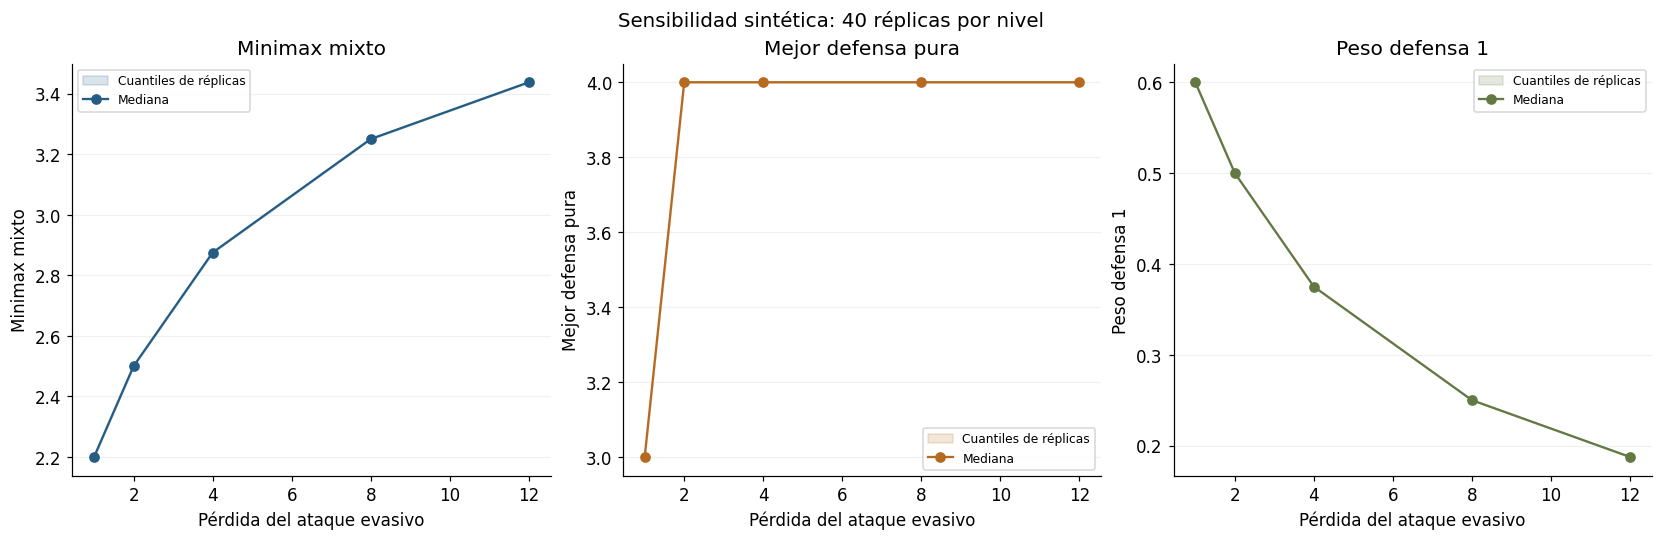

In [5]:
import textwrap
fig,axes=plt.subplots(1,len(METRICS),figsize=(15,4.8),layout='constrained')
for index,(ax,name) in enumerate(zip(np.atleast_1d(axes),METRICS)):
    group=summary[summary.metrica==name].sort_values('nivel')
    ax.fill_between(group.nivel,group.q025,group.q975,color=COLORS[index%3],alpha=.17,label='Cuantiles de réplicas')
    ax.plot(group.nivel,group.mediana,'o-',color=COLORS[index%3],label='Mediana')
    ax.set(title='\n'.join(textwrap.wrap(name,25)),xlabel='\n'.join(textwrap.wrap('Pérdida del ataque evasivo',30)),ylabel=name)
    ax.grid(axis='y',alpha=.18); ax.legend(fontsize=8)
fig.suptitle('Sensibilidad sintética: 40 réplicas por nivel',fontsize=13)
plt.show()


## Lectura de resultados ejecutados

El contraste siguiente se calcula con las salidas de la ejecución, sin fijar de antemano el signo de la conclusión. Debe interpretarse junto con los supuestos y la variación entre réplicas.

In [6]:
for name in METRICS:
    group=summary[summary.metrica==name].sort_values('nivel')
    first,last=group.iloc[0],group.iloc[-1]
    print(f"{name}: mediana {first['mediana']:.6g} en nivel {first['nivel']:g}; "
          f"{last['mediana']:.6g} en nivel {last['nivel']:g}.")
    print(f"  Último escenario: cuantiles [{last['q025']:.6g}, {last['q975']:.6g}], "
          f"media {last['media']:.6g}, error MC de la media {last['se_media_mc']:.3g}.")


Minimax mixto: mediana 2.2 en nivel 1; 3.4375 en nivel 12.
  Último escenario: cuantiles [3.4375, 3.4375], media 3.4375, error MC de la media 0.
Mejor defensa pura: mediana 3 en nivel 1; 4 en nivel 12.
  Último escenario: cuantiles [4, 4], media 4, error MC de la media 0.
Peso defensa 1: mediana 0.6 en nivel 1; 0.1875 en nivel 12.
  Último escenario: cuantiles [0.1875, 0.1875], media 0.1875, error MC de la media 0.


## Comprobaciones y controles

La reproducibilidad exige que la misma semilla reconstruya las mismas métricas. Los asserts estructurales de la función no dependen de que un estimador estocástico gane a otro en esta realización. Los conteos se reconcilian para no perder réplicas silenciosamente.

In [7]:
repeated,_=experiment(np.random.default_rng(SEED),central)
assert all(np.isclose(example[k],repeated[k],rtol=0,atol=1e-12) for k in METRICS)
assert len(raw)==len(GRID)*REPLICATIONS*len(METRICS)
assert summary.n.eq(REPLICATIONS).all()
assert (summary.q025<=summary.mediana+1e-12).all()
assert (summary.mediana<=summary.q975+1e-12).all()
print('Semilla, finitud, cuantiles y totalidad de réplicas: correctos.')


Semilla, finitud, cuantiles y totalidad de réplicas: correctos.


## Límites y siguiente contraste

La matriz no fue estimada con fraude real. Adaptación, costos de inspección y múltiples períodos quedan fuera.

Antes de incorporar datos observados se debe fijar unidad de análisis, fecha de disponibilidad, reglas de exclusión y población de evaluación. La ampliación demuestra un mecanismo acotado; no convierte el proyecto en modelo validado externamente.

## Trazabilidad

Desarrollo semanal sobre `865c326`, revisión del 18-10-2026 UTC (noche del 17-10 en Colombia). El historial Git conserva el baseline genérico anterior. Todos los datos nuevos se regeneran desde la función `experiment`; las salidas del notebook se guardan después de ejecutar sus celdas de principio a fin.